# FindingBench (RAB v1) 项目全景研究日志（Research Journal · V2 真实家庭布景版）

> **记录时间**：2026-11-20 JST  
> **工作区与默认资产版本**：`/home/ubuntu/ygwang/FindingBench` · `runs/rab_lived_in_20261120/combined_manifest.json`（**V2 全屋 10 大生活区满配“烟火气”版**：全量 1,000 条场景累计新增 **+29,030 件** 日常物品，场均 **~37.9 件** 真实家居刚体，46 种原生 USD 物品模型）  
> **公开交互协议**：`findingbench_rab_pinhole_v1`（机器人头部 `1280×720` 针孔相机 + 固定 9 公共技能 + 零闲置显存 Stdio MCP 服务）  
> **写作目的**：用最直白清晰的自然语言（“人话”）完整梳理整套项目的科学故事、数据集全貌、一条完整数据（`rab_F065`，含 **41 件刚体** 的全屋实景渲染图、双 UI 截图、4 抽屉/收纳格内部构造与完整 JSON 源码）、底层关键实现细节、算力边界排查以及目前取得的全部定量与定性实验结果——**看完这份 Journal，我们就正式进入下一步：Metrics 指标体系设计。**


---
## 一、用“人话”讲透：我们在研究什么？研究方法的核心逻辑是什么？

### 1.1 先看一个最真实的家庭场景痛点
假设你在家里对机器人随口说一句最自然的话：
> **“去客厅找一下那个小房子玩具，把它放到茶几桌面上。”**（`rab_F065`）

在一个**真正有人住的正常人类家庭**里（而不是除了目标之外四壁皆空的仿真样板间），机器人面对的真实挑战是什么？
1. **满屋子都是正常生活陈设，目标藏在闭合抽屉或遮挡物后面（不完全观测 + 视觉甄别 + 空间记忆）**：
   - 客厅木茶几桌面上本来就摆着铁盒曲奇罐、可乐罐、气泡水罐、收纳袋和泰迪熊玩偶，正后方黑色电视柜的 4 个开放格里放着遥控器、眼镜盒、玩具小火车和毛绒玩具，沙发边几、餐厅餐桌、厨房操作台、储物架上也全都有日常用品——**没有任何一张桌子是“因为空着或者只有它有东西所以一眼看出是考点”的！**
   - 茶几桌面上并没有小房子玩具；茶几底下并排有 **4 个黑色抽屉/收纳格**。如果机器人先拉开了第三个抽屉（`drawer_alt`），里面放着毛绒兔子、黄色积木块和小机器人——都很像儿童玩具，但都不是小房子。机器人必须**认出它们不是目标**，**记住“这个抽屉已经搜过了”**，再去拉最左边的抽屉（`drawer`）。
2. **近距离稠密干扰与低矮几何约束（局部搜索分支 + 全身运动学挑战）**：
   - 左边抽屉拉开后，内部底板离地仅 **`20 cm`**（上方桌板净高仅 **`18.5 cm`**），目标粉顶小房子（`cloth_clear_house`）被前面的小机器人和毛绒兔子半挡在抽屉深处；在开放台面任务（如 `rab_F251`）中，目标更是直接被前景障碍物挡住抓取路径，往往需要先看清甚至先挪开遮挡物。
3. **有分寸的家庭助手礼仪（准确送达 + 顺手复原）**：
   - 拿到小房子后，要在摆有日常物品的茶几桌面上找一块空地稳稳放下；同时，**拉开的抽屉应该顺手推回去关好，挪动过的其他物品尽量归位**——而且主任务指令里**绝不人工提示**“记得用 CHECK”“记得关抽屉”“最后调 REPORT_DONE”。

---

### 1.2 核心科学主张：为什么要把“高层大脑”和“低层手脚”用固定 9 技能边界解耦？
过去做具身智能评测最头疼的问题是：**当端到端模型拿了 `0` 分时，你根本分不清它是“脑子没想明白”，还是“手脚差一口气”**。

因此，FindingBench 的核心科学贡献是建立**可严格对照、可因果归因的高低层解耦评测范式（`findingbench_rab_pinhole_v1`）**：
- **高层规划层（VLM / Agent）**：只接收 **① 自然语言指令**、**② `1280×720` 第一视角针孔 RGB 图像（及主动调用 `CHECK` 时的 `720×450` 隔离四视图）**、**③ 历史动作与公开反馈码**；每一步只能在 **9 个公共技能**（`MOVE_TO`, `TURN`, `VIEW`, `OPEN`, `CLOSE`, `CHECK`, `GRASP`, `PLACE`, `REPORT_DONE`）中选择一个，并在当前主画面上点一个归一化像素坐标 `(x, y) ∈ [0, 1]²`。
- **低层执行层（契约式几何与物理裁判）**：**绝不替高层做语义思考，也绝不混入手指摩擦打滑或速度 PID 漂移的控制噪声**！它只做严格、透明的三维几何与物理可行性验证：
  - 导航：**2D BEV A\* 寻路 + 5 射线走廊净空检查 + 360° 站立包络无碰撞检查** $	o$ 通过则底盘直接精准落位；
  - 抓取/放置：**9-DoF 全身雅可比 IK 可达性检查（含低矮空间自动俯身种子）+ 机械臂射线无碰撞遮挡检查** $	o$ 通过则直接完成持握挂载或 `8 mm` 上方 65 步原生 PhysX 重力静稳落定！
- **留下的双层铁证**：高层糊涂（不拉抽屉、抓错相似物、忘关抽屉、没拿东西乱报 `REPORT_DONE`）与低层受限（`IK_UNREACHABLE`、`COLLISION_BLOCKED`、`UNSAFE`）在评测账本中泾渭分明！

---

### 1.3 学术坐标与数学形式化直觉（不吹牛、不撞车）
- **与 Mechanical Search / RAY 的关系**：前人工作已经有稠密遮挡（绝不能说前人假定稀疏！），但它们聚焦固定料箱/桌面的局域翻找；我们将其拓展到**真实家庭跨区搜寻、多容器记忆、精细四视图辨认、交付与环境复原**，并专门服务于现代多模态大模型的高低层失败归因。
- **与 RAB 0.1.7 的关系**：诚实声明复用 RAB 高质量家居资产底座，不把“造资产”包装成最大创新；我们的核心创新在于**可诊断的高低层解耦协议、稠密遮挡/双抽屉物理重绑定与全屋生活化场景下的科学对照实验**。
- **数学支撑（`docs/household_search_formalization.md`）**：即使把房间移动距离降为零，$n$ 个等先验候选位点的理想单次检查期望步数仍为 $\mathbb{E}[C] = rac{n+1}{2}$（独立可分代价下满足 $q_i / p_i$ 交换论证最优序）；而真实开柜、移挡与复原构成强耦合部分可观测问题（POMDP），从理论上说明**局部候选分支与遮挡可独立于移动距离产生显著规划复杂度**。


---
## 二、数据集全貌与 V2 全屋 10 大生活区“烟火气”升级（一眼真家庭，绝非空壳仿真）

### 2.1 1,000 条场景底盘账本
- **规模与房型实情**：共 **50 个室内陈设布局 × 20 条任务 = 1,000 条场景**（建筑外壳同属 `LIVING_STRAIGHT` 客餐厨一体空间，底层几何审计归属 **6 组外壳签名**，如实披露绝不虚报“50 种户型”）。
- **任务机制分层**：**`872` 条双抽屉翻找（`articulated_drawer`）**、**`123` 条开放台面遮挡（`occluded_open`）**、**`5` 条厨房双开门冰箱（`articulated_refrigerator`）**；`400` 条短程 vs `600` 条跨区；目标数 `1 / 2 / 3 / 4` 分别为 `824 / 147 / 26 / 3` 条。

### 2.2 V2 全屋满配“烟火气”语义增强（解决早期台面与电视柜空旷问题）
为了彻底消除“只有考点有东西、其余茶几/电视柜/餐桌光秃秃像样板间”的仿真感，我们在 V2 版（`scripts/rab_enrich_lived_in.py`）中将资产库扩充至 **46 种经 Z 轴平底与刚体校验的日常家居模型**（新增陶瓷马克杯、铁盒曲奇罐、叠放报纸杂志、纸板收纳盒、圆珠笔、餐具收纳架、奶油/原味小蛋糕、果味气泡水罐等），并在**严格保留主任务目标、遮挡关系及 $\ge 26\text{ cm}$ 终点交付净空区**的前提下，铺满全屋 **10 大真实生活区域**：

1. **`coffee`（客厅大木茶几台面，保底 5 件立体日常物）**：曲奇铁盒、可乐罐、马克杯/纸杯、遥控器、书本/报纸、泰迪熊等错落摆放，同时留出干净的交付落点；
2. **`tv_console`（茶几正后方黑色 4 格开放式电视柜隔板，5 件）**：自动按中间立柱拆分为左右 × 上下 4 个开放储物格（限高 `≤ 11.5 cm`），放入收纳盒、遥控器、眼镜盒、小火车、玩偶、书籍，彻底告别黑洞洞的空柜子；
3. **`drawer` + `drawer_alt` + `cubby_2` + `cubby_4`（茶几下方并排全部 4 个黑色抽屉/收纳格）**：不仅两个带滑轨的主副抽屉里有物品，连中间和最右侧的两个开放黑收纳筐也装入了折叠报纸、笔记本、收纳包和积木，4 个格子无一空白；
4. **`side`（沙发旁边几，4 件）** & **`dining`（餐厨区餐桌 `KitchenTable53` / `KitchenCoffeeTable03`，5 件）**：自动避开咖啡磨豆机与微波炉，摆上果汁、小蛋糕、刀叉、饼干盒与水杯；
5. **`counter`（厨房长操作台，6 件）** & **`shelf`（储物间多层铁艺架，7 件）**：自动避开洗菜盆镂空洞、空气炸锅与机器人出生时悬停的手臂包络。

> **全量统计**：1,000 条场景累计新增 **`+29,030` 件** 生活化物品（场均新增 **`29.03` 件**，加上原任务物品后全屋场均达 **`~37.9` 件**！）。先直接看下方刚刚在原生 Isaac Sim / PhysX 中实拍的 **`rab_F065`（全屋 41 件刚体，75 步 PhysX 最大漂移仅 `4.03 mm`）四视角实景照片**：


{
  "version": "v2_full_home_lived_in",
  "total_added_items": 29030,
  "mean_added_items_per_episode": 29.03,
  "added_by_zone": {
    "coffee": 3110,
    "tv_console": 5000,
    "side": 2680,
    "dining": 2600,
    "counter": 5898,
    "shelf": 6240,
    "cubby_2": 1258,
    "cubby_4": 1527,
    "drawer": 368,
    "drawer_alt": 349
  },
  "asset_catalog_count": 46,
  "parent_release": "/home/ubuntu/ygwang/FindingBench_20261016_200444/workspace/runs/rab_dense_serial_20261119",
  "parent_manifest_sha256": "715ea3f8f5fe7ae5e274968d4c70e1ca1c006e3aa0d529126da812536848667e"
}


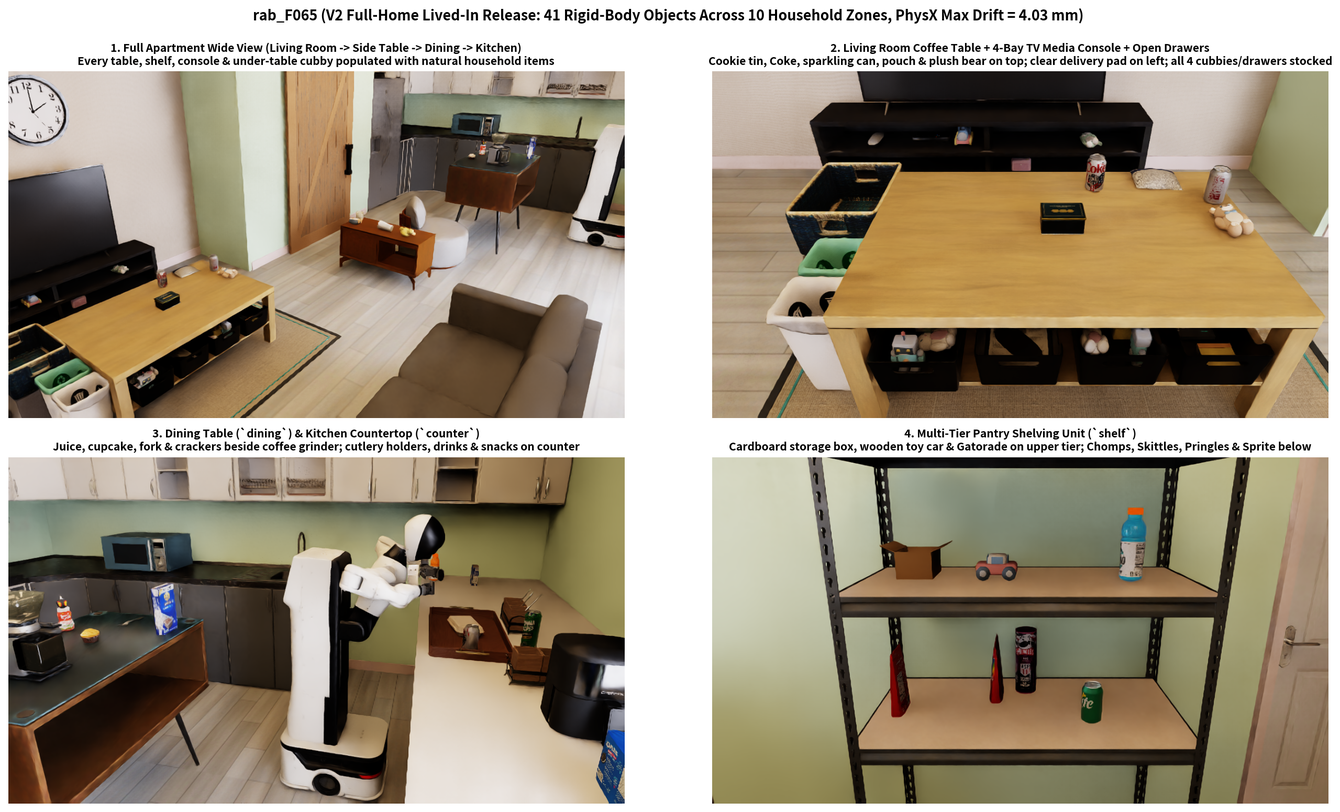

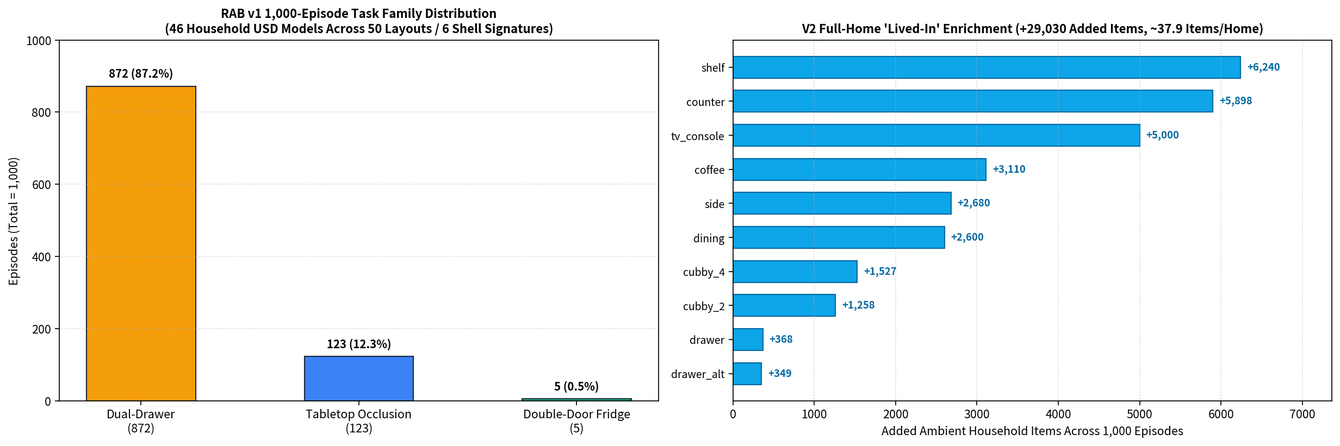

In [1]:
# V2 全屋生活化增强统计 + rab_F065 全屋 4 视角原生 RTX 实景照片展示
import json
ENRICHMENT_V2 = json.loads(r'''{
  "version": "v2_full_home_lived_in",
  "total_added_items": 29030,
  "mean_added_items_per_episode": 29.03,
  "added_by_zone": {
    "coffee": 3110,
    "tv_console": 5000,
    "side": 2680,
    "dining": 2600,
    "counter": 5898,
    "shelf": 6240,
    "cubby_2": 1258,
    "cubby_4": 1527,
    "drawer": 368,
    "drawer_alt": 349
  },
  "asset_catalog_count": 46,
  "parent_release": "/home/ubuntu/ygwang/FindingBench_20261016_200444/workspace/runs/rab_dense_serial_20261119",
  "parent_manifest_sha256": "715ea3f8f5fe7ae5e274968d4c70e1ca1c006e3aa0d529126da812536848667e"
}''')
print(json.dumps(ENRICHMENT_V2, indent=2, ensure_ascii=False))


---
## 三、解剖麻雀：一条完整数据（`rab_F065`）的 UI 界面、4 抽屉内部构造与完整 JSON 源码

### 3.1 真实交互 UI 截图与茶几下方 4 抽屉/收纳格微距特写
- **图 A（左上）：公开 9 技能试玩界面（`play_data.py F065`）** —— 智能体或人类试玩者只能看到自然语言指令 `Could you look for the toy house in the living room and put it on the coffee table?`、当前 `1280×720` 第一视角画面（茶几上摆满日常物品、后方电视柜隔板有陈设、下方抽屉已拉开）以及 9 个公共技能按钮。
- **图 B（右上）：`CHECK` 技能隔离四视图卡片（`720×450`）** —— 点选抽屉深处的候选物体后返回的四个正交方向特写，用于看清细节辨别真伪，但**强制 `point_selectable = false` 严禁在放大图上直接点击抓取**。
- **图 C（左下）：开发者特权场景编辑器（`spectator.py --task F065 --edit`）** —— 仅供离线巡检与资产管理，评测期间彻底物理隔离。
- **图 D（右下）：茶几底下并排 4 个抽屉/收纳格微距实拍** —— 最左格 `drawer` 拉开后，前方是小机器人与毛绒兔干扰物，**正后方露出粉色屋顶的目标小房子 `cloth_clear_house`**；旁边 `cubby_2`（报纸+眼镜盒）、`drawer_alt`（毛绒兔+黄积木+机器人）、`cubby_4`（收纳盒+便签）全部真实填充！


Displaying UI screenshots, 4-drawer close-up, and metric CAD floorplan of V2 rab_F065:


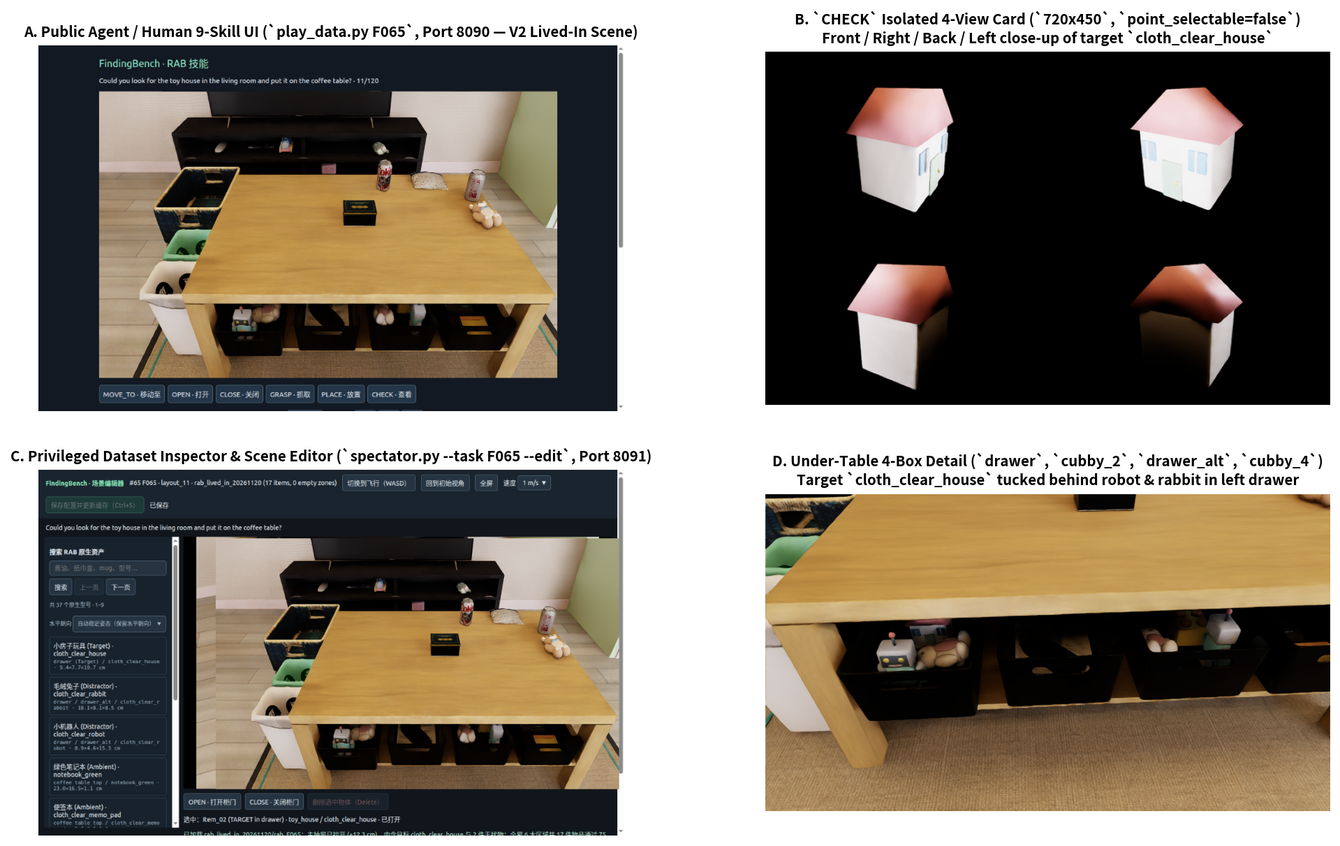

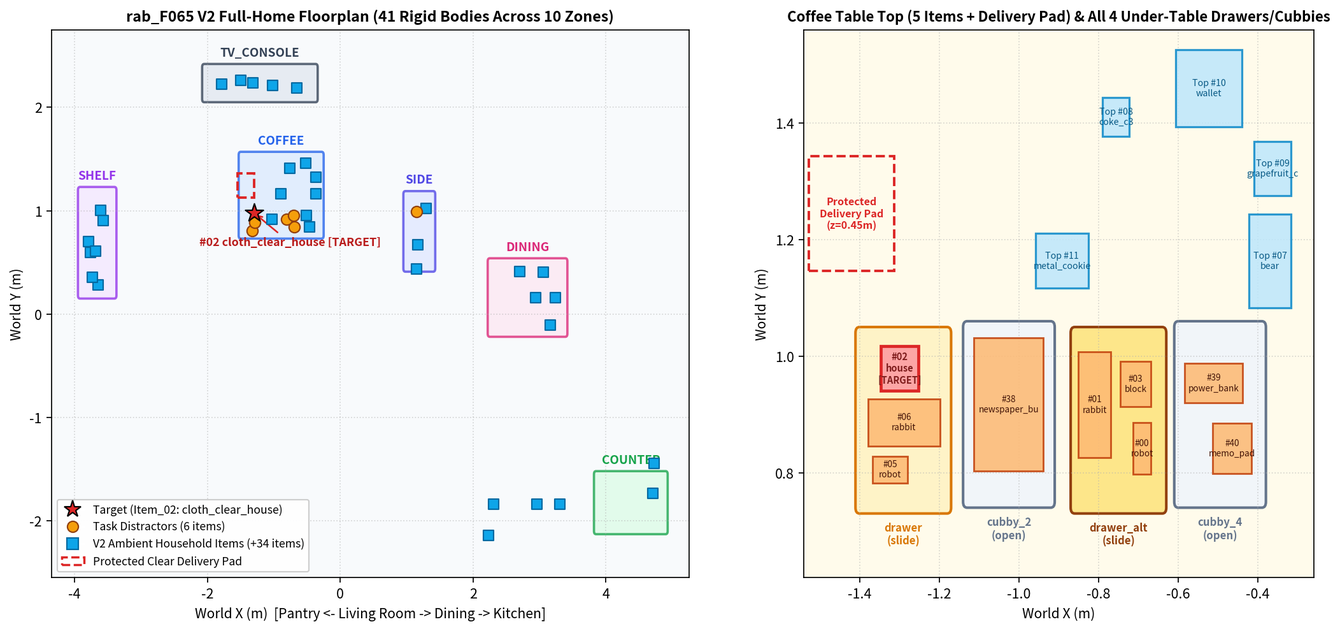

In [2]:
# 展示 rab_F065 的双 Web UI 截图、CHECK 四视图卡片、茶几 4 抽屉特写与全屋 41 刚体 CAD 平面图
print('Displaying UI screenshots, 4-drawer close-up, and metric CAD floorplan of V2 rab_F065:')


### 3.2 附：`rab_F065` 完整单条数据 JSON（全量 41 件刚体，一字不漏）与公私字段边界说明
- **公开给被测模型的字段**：仅 `id`（调用 `reset_episode` 用）和 `instruction`（自然语言指令），外加运行时实时渲染的 PNG 图像、`frame_id`、当前步数与动作反馈码。
- **严格锁在评测器后台的私有字段**：`scene`（USD 路径与 SHA256 防篡改锁）、`placed[0..40]`（全部 **41 件物品**的精确三维包围盒、`target: true/false` 身份标签、承托网格路径）、`delivery`（终点茶几承托面判据）、`arrangement`（滑轨关节路径）以及 `native_validation.json` 中的 **75 步原生 PhysX 静稳检验回执（41 件物品全部 `stable: true`，最大初态沉降仅 `4.03 mm`）** 和 `restoration_reference` 初始位姿基准账本。


In [3]:
# 完整单条数据源码：runs/rab_lived_in_20261120/cases/rab_F065/episode.json (共 41 件物品) + 原生 PhysX 验证摘要
import json
EPISODE_F065_V2 = json.loads(r'''{
  "id": "rab_F065",
  "parent_task_id": "F065",
  "layout_id": 11,
  "regime": "short_range",
  "instruction": "Could you look for the toy house in the living room and put it on the coffee table?",
  "baseline_instruction": "Could you find the toy house in the living room and set it on the coffee table?",
  "original_instruction": "Four people are having cereal at the table in front of you in the kitchen. Check the bowls already there and find enough more in the kitchen cupboards so everyone has one.",
  "source_backup_sha256": "3512c1709f54f9aabc356793eb7adaa1982935a61ce3d85561aae707689c9a53",
  "baseline_scene_sha256": "20e7c1a861f7f9ca1035b97899e6a183dc03adaeca1aada978e7d47e18e5ca2a",
  "scene": "/home/ubuntu/ygwang/FindingBench_20261016_200444/workspace/runs/rab_lived_in_20261120/cases/rab_F065/scene.usda",
  "scene_sha256": "32298e271ea28e7c55023fbe906881048c3b394166750dabcd882ea37a67743e",
  "placed": [
    {
      "body": "/World/FindingBench/Item_00/Model",
      "asset": "cloth_clear_robot",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_3/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -0.7140811191637095,
          0.7970570200897157,
          0.20680777654414345
        ],
        [
          -0.6685713544443999,
          0.885961486642383,
          0.35931271603577974
        ]
      ],
      "zone": "drawer_alt",
      "source_sha256": "4e1d9281a7f8aa07991190440500002f1b28b4dcf5e6ebb3ee910e30303e0cf8"
    },
    {
      "body": "/World/FindingBench/Item_01/Model",
      "asset": "cloth_clear_rabbit",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_3/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -0.8505464958084035,
          0.8259570594628769,
          0.20138229082132825
        ],
        [
          -0.7694140891943844,
          1.0070190218158304,
          0.28677072124746245
        ]
      ],
      "zone": "drawer_alt",
      "source_sha256": "273b8226196eed07a9ef8040f792c85e798284b22f540a57707fa0061c38a4dc"
    },
    {
      "body": "/World/FindingBench/Item_02/Model",
      "asset": "cloth_clear_house",
      "target": true,
      "support": "/World/Assets/CoffeeTable/black_box_1/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -1.3464367480916681,
          0.9407712757271003,
          0.20623089429158994
        ],
        [
          -1.2522282003853473,
          1.0173369032015598,
          0.31315369358286216
        ]
      ],
      "zone": "drawer",
      "source_sha256": "6465ed02e409bb8fc37bb2dc311c39ea2050fd38df57c007299459ebed19c8d3"
    },
    {
      "body": "/World/FindingBench/Item_03/Model",
      "asset": "cloth_clear_block",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_3/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -0.7455732490728588,
          0.9137084333477496,
          0.20603656054047662
        ],
        [
          -0.6685713544443999,
          0.9912418059702717,
          0.265278378212333
        ]
      ],
      "zone": "drawer_alt",
      "source_sha256": "b6450840099f6a547a021c1dad684d34a0025d5eb82d6d9ac4ceacf640a0f034"
    },
    {
      "body": "/World/FindingBench/Item_04/Model",
      "asset": "cloth_clear_penguin",
      "target": false,
      "support": "/World/Assets/SmallCoffeeTable/geo/组003/Rectangle058/Rectangle058",
      "expected_bounds_m": [
        [
          1.0955943673670434,
          0.923077732596209,
          0.4521845156845802
        ],
        [
          1.1930741756359582,
          1.0636535402344407,
          0.5318774062002435
        ]
      ],
      "zone": "side",
      "source_sha256": "14626ec130a1bbd1a7ce73bf3418d29db3f71d50c8c6fc3b6b5e42b31dfd0335"
    },
    {
      "body": "/World/FindingBench/Item_05/Model",
      "asset": "cloth_clear_robot",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_1/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -1.3677147590842933,
          0.7824838126880072,
          0.20666173022283477
        ],
        [
          -1.2788102925316263,
          0.8279935774073168,
          0.3591666697144711
        ]
      ],
      "zone": "drawer",
      "source_sha256": "4e1d9281a7f8aa07991190440500002f1b28b4dcf5e6ebb3ee910e30303e0cf8"
    },
    {
      "body": "/World/FindingBench/Item_06/Model",
      "asset": "cloth_clear_rabbit",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_1/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -1.3787791111089818,
          0.8458196313667565,
          0.20123624450001956
        ],
        [
          -1.1977171487560283,
          0.9269520379807759,
          0.28662467492615373
        ]
      ],
      "zone": "drawer",
      "source_sha256": "273b8226196eed07a9ef8040f792c85e798284b22f540a57707fa0061c38a4dc"
    },
    {
      "body": "/World/FindingBench/Item_07/Model",
      "asset": "cloth_clear_bear",
      "target": false,
      "support": "/World/Assets/CoffeeTable/Mesh",
      "expected_bounds_m": [
        [
          -0.42203928539935476,
          1.0831106209798187,
          0.4455526655132748
        ],
        [
          -0.3167604965363856,
          1.2437157840948552,
          0.5138064322918432
        ]
      ],
      "zone": "coffee",
      "source_sha256": "c8b4fefcc2a0cade08e0ffa34142d897917ca97ae45a3a46f32f1cd419db09d1",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_08/Model",
      "asset": "coke_c3",
      "target": false,
      "support": "/World/Assets/CoffeeTable/Mesh",
      "expected_bounds_m": [
        [
          -0.7895132607362427,
          1.37731710950661,
          0.4529999870434406
        ],
        [
          -0.7231087931493256,
          1.443719941732185,
          0.5750024076593022
        ]
      ],
      "zone": "coffee",
      "source_sha256": "30f4759f40e15bc6606dfd7557b95a7844454dfc99032e36ba8c7d9e979bb5fa",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_09/Model",
      "asset": "grapefruit_can",
      "target": false,
      "support": "/World/Assets/CoffeeTable/Mesh",
      "expected_bounds_m": [
        [
          -0.4095489009811023,
          1.2751594893149,
          0.4530000073909762
        ],
        [
          -0.3167604965363856,
          1.367947893759617,
          0.5750000094473364
        ]
      ],
      "zone": "coffee",
      "source_sha256": "74605130c2e42fbd64827240cd92e966a984e95e9303ed405b3a29975f0d6ed7",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_10/Model",
      "asset": "wallet",
      "target": false,
      "support": "/World/Assets/CoffeeTable/Mesh",
      "expected_bounds_m": [
        [
          -0.6066479302588954,
          1.3935620426526525,
          0.44474012889647346
        ],
        [
          -0.4396337096076591,
          1.5260883827595386,
          0.5011286836162983
        ]
      ],
      "zone": "coffee",
      "source_sha256": "25bb9146e2824ee04f06de2fe4ac6bf6574c3202d0760457e27136ae0fb2112f",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_11/Model",
      "asset": "context_trash_metal_cookie_tin",
      "target": false,
      "support": "/World/Assets/CoffeeTable/Mesh",
      "expected_bounds_m": [
        [
          -0.9587604608160276,
          1.1164132041466623,
          0.45300000670552276
        ],
        [
          -0.8247604574781675,
          1.2104132009280115,
          0.5152000053524973
        ]
      ],
      "zone": "coffee",
      "source_sha256": "722279451865e94278f24569cc806aac0336d041c7102ed847862df6acd39b3a",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_12/Model",
      "asset": "cloth_clear_train",
      "target": false,
      "support": "/World/Assets/TvTable/Obj/Meshes/FAB_converted_model/tv_table_fbx/RootNode/P0627_Media_Storage01/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0",
      "expected_bounds_m": [
        [
          -1.365648181613155,
          2.162290032838144,
          0.29734961335626536
        ],
        [
          -1.2755081627462874,
          2.3082898913961976,
          0.4013499877159397
        ]
      ],
      "zone": "tv_console",
      "source_sha256": "0a6c429ea04102054bd453414f5863d3a460332668af6809934f1638ca9a9500",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_13/Model",
      "asset": "remote_tv",
      "target": false,
      "support": "/World/Assets/TvTable/Obj/Meshes/FAB_converted_model/tv_table_fbx/RootNode/P0627_Media_Storage01/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0",
      "expected_bounds_m": [
        [
          -1.6024176284391591,
          2.2325256769397916,
          0.29713001848448023
        ],
        [
          -1.4015383241230375,
          2.2898365638697764,
          0.3213992480774012
        ]
      ],
      "zone": "tv_console",
      "source_sha256": "58435180c299721e0750f9bb6b85fa09ab286a78c5e50582d0f9c6d34e0a8c60",
      "pose_variant": "calibrated_mesh_footprint",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_14/Model",
      "asset": "glasses_case",
      "target": false,
      "support": "/World/Assets/TvTable/Obj/Meshes/FAB_converted_model/tv_table_fbx/RootNode/P0627_Media_Storage01/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0",
      "expected_bounds_m": [
        [
          -1.8196362903752814,
          2.138230027392299,
          0.29198424334388695
        ],
        [
          -1.758123629328672,
          2.3089098022483254,
          0.3328615407074169
        ]
      ],
      "zone": "tv_console",
      "source_sha256": "4079251ce47ee46896457f5afce29feb0c7ce5826d3ff4c219d09c2951525a06",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_15/Model",
      "asset": "cloth_clear_pouch",
      "target": false,
      "support": "/World/Assets/TvTable/Obj/Meshes/FAB_converted_model/tv_table_fbx/RootNode/P0627_Media_Storage01/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0",
      "expected_bounds_m": [
        [
          -1.0712180013474786,
          2.1862607796184332,
          0.1344967544602566
        ],
        [
          -0.9605393427148283,
          2.234418231166033,
          0.21598654338631168
        ]
      ],
      "zone": "tv_console",
      "source_sha256": "cc58c68794d64a772dbdc79dc1d12266a85f0294c826f4252cddb8e5cdc616ff",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_16/Model",
      "asset": "cloth_clear_cat",
      "target": false,
      "support": "/World/Assets/TvTable/Obj/Meshes/FAB_converted_model/tv_table_fbx/RootNode/P0627_Media_Storage01/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0/P0627_Media_Storage01_P0627_Media_Storage01_MAT01_0",
      "expected_bounds_m": [
        [
          -0.7166432987343241,
          2.103069885501724,
          0.28483296829972415
        ],
        [
          -0.58346316759382,
          2.2743964660170413,
          0.36735851894140936
        ]
      ],
      "zone": "tv_console",
      "source_sha256": "f2cf6c425cc7eca37319e7871c419d421d065af5950a09dddda85e549955d893",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_17/Model",
      "asset": "paper_cup",
      "target": false,
      "support": "/World/Assets/SmallCoffeeTable/geo/组003/Rectangle058/Rectangle058",
      "expected_bounds_m": [
        [
          1.1247331743102063,
          0.5993416428509728,
          0.44642746644824033
        ],
        [
          1.2138332209624307,
          0.7382917458277234,
          0.5490846055656499
        ]
      ],
      "zone": "side",
      "source_sha256": "ccc9470d208fba48cd9845d6bc73ff7b1caf6ff593f40495fc6a61059a15a0d6",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_18/Model",
      "asset": "cloth_clear_duck",
      "target": false,
      "support": "/World/Assets/SmallCoffeeTable/geo/组003/Rectangle058/Rectangle058",
      "expected_bounds_m": [
        [
          1.0910343545771473,
          0.35160788243655106,
          0.4319869890366557
        ],
        [
          1.2067542140056466,
          0.520257302288372,
          0.5583593526888296
        ]
      ],
      "zone": "side",
      "source_sha256": "d68ddec8ffee5ef2ae11b3f7325c238ec1be52b7d79209a4c087098b5ff8d1a8",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_19/Model",
      "asset": "context_trash_chipped_ceramic_mug",
      "target": false,
      "support": "/World/Assets/SmallCoffeeTable/geo/组003/Rectangle058/Rectangle058",
      "expected_bounds_m": [
        [
          1.2421025537289065,
          0.9816535379694642,
          0.4601573568620393
        ],
        [
          1.349052553657381,
          1.0636535402344407,
          0.5401573550739
        ]
      ],
      "zone": "side",
      "source_sha256": "9eaf2e5adf32da41eabd045b3eafdf4abc607ce4f26202cf0ee79553fb523e23",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_20/Model/Object",
      "asset": "cake_plain_yellow",
      "target": false,
      "support": "/World/Assets/KitchenCoffeeTable03/Mesh",
      "expected_bounds_m": [
        [
          2.8991126617769694,
          0.12110861166998033,
          0.9230000166893005
        ],
        [
          2.9799013710002398,
          0.2007336072592366,
          0.9820000170469284
        ]
      ],
      "zone": "dining",
      "source_sha256": "91e482ee1d0eb51b101b1a4b59a8bdad3adaa414c29fac9761846c190ba7f14c",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_21/Model",
      "asset": "good2grow",
      "target": false,
      "support": "/World/Assets/KitchenCoffeeTable03/Mesh",
      "expected_bounds_m": [
        [
          3.0044053482861734,
          0.355460692910819,
          0.9229937257276772
        ],
        [
          3.1027557063622524,
          0.45379612341209535,
          1.1010022552196406
        ]
      ],
      "zone": "dining",
      "source_sha256": "17a2e1b5f7cb57c11f840f5c2d92131f8014ffb4a62934835ae419c908509794",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_22/Model",
      "asset": "honeymaid",
      "target": false,
      "support": "/World/Assets/KitchenCoffeeTable03/Mesh",
      "expected_bounds_m": [
        [
          3.097350380622751,
          -0.13195390448287841,
          0.9229992417246103
        ],
        [
          3.22235637836241,
          -0.08695213021749314,
          1.1580024553845492
        ]
      ],
      "zone": "dining",
      "source_sha256": "aad560312fe6015581a3f2f7c7038a2425fc9a9c16266516d18a2d89b930c6f5",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_23/Model/Object",
      "asset": "cake_frosted_white",
      "target": false,
      "support": "/World/Assets/KitchenCoffeeTable03/Mesh",
      "expected_bounds_m": [
        [
          2.6621848154793475,
          0.37417112782283907,
          0.9230000166893005
        ],
        [
          2.742973524702618,
          0.45379612341209535,
          0.9820000170469284
        ]
      ],
      "zone": "dining",
      "source_sha256": "2076a36dcba7c6ca936ed90dca43db7167b84ab3c0df21c3ec3d3bc4c2ac5e88",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_24/Model/Object",
      "asset": "meal_fork",
      "target": false,
      "support": "/World/Assets/KitchenCoffeeTable03/Mesh",
      "expected_bounds_m": [
        [
          3.144133347227685,
          0.1396273436349258,
          0.9228884084097315
        ],
        [
          3.335293140446672,
          0.1822148752942911,
          0.9423965642119059
        ]
      ],
      "zone": "dining",
      "source_sha256": "45faadb0c1627cc09ef6126b689e4a7f6dc5b27f114991631f598e08c3111fe9",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_25/Model",
      "asset": "gatorade_m",
      "target": false,
      "support": "/World/Background/Shell/CounterTop_17",
      "expected_bounds_m": [
        [
          4.69277100742316,
          -1.4788270216487573,
          0.9229820763641652
        ],
        [
          4.762948136342513,
          -1.4087975245494273,
          1.1342120356734604
        ]
      ],
      "zone": "counter",
      "source_sha256": "ee3923dffa7e9e285fc5b5838590a3156f98c25348c38d9521cd253bcde88d4d",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_26/Model",
      "asset": "zbar_t",
      "target": false,
      "support": "/World/Background/Shell/CounterTop_17",
      "expected_bounds_m": [
        [
          4.636050893031922,
          -1.757742052255361,
          0.9229999743029476
        ],
        [
          4.771051009826976,
          -1.7177398042771899,
          1.0580006440117544
        ]
      ],
      "zone": "counter",
      "source_sha256": "2712e1d74db88680d45391f2e2fdf229354ac8d2ef8ad1507308546e00f4da08",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_27/Model",
      "asset": "cayman_jacked",
      "target": false,
      "support": "/World/Background/Shell/CounterTop_17",
      "expected_bounds_m": [
        [
          3.26154800846851,
          -1.887078901981161,
          0.9229999995529652
        ],
        [
          3.3542624360797726,
          -1.7943644743698985,
          1.1059999987185
        ]
      ],
      "zone": "counter",
      "source_sha256": "86e6a77afd770225c8f8f8e7026f4330000877cf99e50d713d24d6e7d2e5fadf",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_28/Model",
      "asset": "starbucks",
      "target": false,
      "support": "/World/Background/Shell/CounterTop_17",
      "expected_bounds_m": [
        [
          2.2029208615190883,
          -2.1714213805437907,
          0.9229050575877289
        ],
        [
          2.257104228421128,
          -2.117368823354319,
          1.02602681581831
        ]
      ],
      "zone": "counter",
      "source_sha256": "e156b51e74c0cbc46729fe2aa86e338e41f30e67626da1dd9e4b7d7859541afd",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_29/Model/Object",
      "asset": "cutlery_holder",
      "target": false,
      "support": "/World/Background/Shell/CounterTop_17",
      "expected_bounds_m": [
        [
          2.905807077452835,
          -2.000013314687746,
          0.9229999995529652
        ],
        [
          3.009982366527568,
          -1.681430061663314,
          1.0481441831886769
        ]
      ],
      "zone": "counter",
      "source_sha256": "a834e426ae759c2a61f9304fffe4f6588df04a81960230b1ae63ac0a4bb1191e",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_30/Model",
      "asset": "oreo_gf",
      "target": false,
      "support": "/World/Background/Shell/CounterTop_17",
      "expected_bounds_m": [
        [
          2.2029208615190883,
          -1.86472177096534,
          0.9229999994486571
        ],
        [
          2.4079209133435575,
          -1.8167216053857198,
          1.0580000432183807
        ]
      ],
      "zone": "counter",
      "source_sha256": "da57ce1c2f8ae794a69a518634da0edc2a442372e336ad637d7e6b248e2e680a",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_31/Model",
      "asset": "chomps_r",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.7100017659739275,
          0.26142027056806266,
          0.7540013094767806
        ],
        [
          -3.5899982340260714,
          0.3054227902587257,
          0.9640036149921637
        ]
      ],
      "zone": "shelf",
      "source_sha256": "493aa0de302e3960d5a398fdc1aa6d83a5bef080da07ca3da59f7383bbf5758a",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_32/Model",
      "asset": "gatorade_t",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.6472155974349714,
          0.9671190476691899,
          1.185452815553079
        ],
        [
          -3.577161118902285,
          1.037460799897298,
          1.396718508179142
        ]
      ],
      "zone": "shelf",
      "source_sha256": "c52584212ee2d1f3d27e4b5052e13f97072cfead7b86a0e219d2465fdcb103f7",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_33/Model",
      "asset": "sprite_c1",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.60643680370669,
          0.8694884446688066,
          0.7540005634873983
        ],
        [
          -3.5400333149664487,
          0.9358903380650213,
          0.8760031081047134
        ]
      ],
      "zone": "shelf",
      "source_sha256": "c8b1fccdaaaf7921ee29a85e5fbd1327164cbed7177e1c390b79e31fadf195e2",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_34/Model",
      "asset": "skit_littles",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.8367316256969803,
          0.5723548672071775,
          0.7540009816512343
        ],
        [
          -3.6867302931767854,
          0.6203554017000777,
          0.954002027936763
        ]
      ],
      "zone": "shelf",
      "source_sha256": "37ee242e6cdfa97e4757863faf3e9a86ab643b04fe7b190a3a3e5b94083296d7",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_35/Model",
      "asset": "context_trash_cardboard_box",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.80845535568893,
          0.2617758921749527,
          1.1855006619281911
        ],
        [
          -3.6584553497284653,
          0.45408589760135953,
          1.2870406611747884
        ]
      ],
      "zone": "shelf",
      "source_sha256": "931c2f976025f0b85241630b59ae18e00b91c6595faed19dd19c9233c4cbb69e",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_36/Model",
      "asset": "pring_bbq",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.8367316256969803,
          0.6574984574494068,
          0.7540017471983906
        ],
        [
          -3.7517286949294806,
          0.7425015425505918,
          0.9840096817204231
        ]
      ],
      "zone": "shelf",
      "source_sha256": "d2eb276334a6190373f997e9120f6325c1dee8706fc085bb8f854a80619a0338",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_37/Model",
      "asset": "cloth_clear_car",
      "target": false,
      "support": "/World/Assets/ShelvingUnit/o/Meshes/Sketchfab_model/root/GLTF_SceneRootNode/shelf_boards_0/Object_4/Object_0",
      "expected_bounds_m": [
        [
          -3.7338584573534743,
          0.542631469536913,
          1.1855006506480121
        ],
        [
          -3.6344184421387618,
          0.6701314788884454,
          1.259000681284709
        ]
      ],
      "zone": "shelf",
      "source_sha256": "747fedefd7705504deda801733c12739b215145b43a4fd076126768669dcc70e",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_38/Model",
      "asset": "context_trash_newspaper_bundle",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_2/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -1.1124439988032988,
          0.8029411204092939,
          0.2068111917591688
        ],
        [
          -0.938554004182022,
          1.0316911257737118,
          0.22063119175201623
        ]
      ],
      "zone": "cubby_2",
      "source_sha256": "36234d32903ebff2c5b23a3dae074ae4b67736911b21db274401b77bf180a33a",
      "pose_variant": "zup_native",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_39/Model",
      "asset": "power_bank",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_4/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -0.5841533523638384,
          0.919855204983544,
          0.2068445500254611
        ],
        [
          -0.43904825601204955,
          0.9878556704654788,
          0.22302512091993373
        ]
      ],
      "zone": "cubby_4",
      "source_sha256": "479d23e54d1f94795909625f1cc81930e6146f9cf01c9464a7fb87de4b68cf18",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    },
    {
      "body": "/World/FindingBench/Item_40/Model",
      "asset": "cloth_clear_memo_pad",
      "target": false,
      "support": "/World/Assets/CoffeeTable/black_box_4/box/Geom/Meshes/FAB_converted_model/root/GLTF_SceneRootNode/Box_1/Bottom_0/Object_6/Object_1",
      "expected_bounds_m": [
        [
          -0.5141744607777337,
          0.7989168027462648,
          0.20684452953636445
        ],
        [
          -0.4161743716204531,
          0.8849169048634349,
          0.24034475863824528
        ]
      ],
      "zone": "cubby_4",
      "source_sha256": "659657cbbe22203d1167dbef639b638e002955f04300db2d3650efbf3369d915",
      "pose_variant": "calibrated",
      "ambient_enrichment": true
    }
  ],
  "original_recipe": {
    "initial_relations": [
      {
        "entity": "item_00",
        "relation": "inside",
        "receptacle": "bottom_cabinet_no_top_pluwfl_0"
      }
    ],
    "original_search_distractors": 0,
    "closed_container_required": true,
    "original_initial_states": {
      "bottom_cabinet_no_top_pluwfl_0": {
        "open": false
      }
    },
    "target_count": 1
  },
  "search_fixture": "drawer",
  "alternative_search_fixture": "drawer_alt",
  "minimum_distractors": 6,
  "measured_drawer_headroom_m": {
    "drawer": 0.18464487740067337,
    "drawer_alt": 0.18449883107936468
  },
  "delivery": {
    "relation": "on_top",
    "fixture": "coffee",
    "placements": [
      {
        "asset": "cloth_clear_house",
        "support": "/World/Assets/CoffeeTable/Mesh",
        "bounds_m": [
          [
            -1.4667604217578096,
            1.2062284804213501,
            0.45256841071074894
          ],
          [
            -1.3725518740514888,
            1.2827941078958096,
            0.5594912100020211
          ]
        ]
      }
    ]
  },
  "arrangement": {
    "kind": "articulated_drawer",
    "articulations": {
      "drawer": "/World/Assets/CoffeeTable/black_box_1_slide",
      "drawer_alt": "/World/Assets/CoffeeTable/black_box_3_slide"
    },
    "shield": null
  },
  "pre_enrichment_scene_sha256": "5a42b2d4297cb1309753c5ca24a6c05d3b54418212984f3d7ed1a14cbf84ef4a",
  "ambient_enrichment_count": 34
}''')
PHYSX_RECEIPT_F065_V2 = json.loads(r'''{
  "status": "physx_initialization_pass",
  "physx_lived_in_verified": true,
  "steps": 75,
  "verified_rigid_body_count": 41,
  "all_41_objects_stable": true,
  "max_initial_drift_m": 0.004028,
  "dense_drawer_slide_checks": [
    {
      "zone": "drawer_alt",
      "passed": true,
      "open_travel_m": 0.15002167224885218,
      "close_error_m": 5.555156090739562e-05,
      "drawer_item_open_drift_m": [
        0.00015572986482300456,
        0.00036392955251248496,
        0.0006112703557204158
      ],
      "drawer_item_close_drift_m": [
        0.00015843734460319235,
        0.0007388895962084083,
        0.0006113152451830813
      ],
      "exterior_item_drift_m": [
        0.0,
        0.0,
        0.0,
        0.0
      ]
    },
    {
      "zone": "drawer",
      "passed": true,
      "open_travel_m": 0.14997565746308558,
      "close_error_m": 1.1563339491416627e-05,
      "drawer_item_open_drift_m": [
        0.0003960269118544917,
        0.00035891119480895836,
        0.00039132299582845284
      ],
      "drawer_item_close_drift_m": [
        0.0003969337589958686,
        0.00035807977005155347,
        0.00038646355957447256
      ],
      "exterior_item_drift_m": [
        0.0001721172774289716,
        0.0007406698508543658,
        0.0006142385523180639,
        0.0
      ]
    }
  ],
  "restoration_scales": {
    "position_m": 0.05,
    "angle_rad": 0.35,
    "slide_m": 0.04
  }
}''')
print('=== PHYSX RECEIPT SUMMARY ===')
print(json.dumps(PHYSX_RECEIPT_F065_V2, indent=2, ensure_ascii=False))
print('\n=== COMPLETE EPISODE JSON (rab_F065, 41 Placed Objects) ===')
print(json.dumps(EPISODE_F065_V2, indent=2, ensure_ascii=False))


=== PHYSX RECEIPT SUMMARY ===
{
  "status": "physx_initialization_pass",
  "physx_lived_in_verified": true,
  "steps": 75,
  "verified_rigid_body_count": 41,
  "all_41_objects_stable": true,
  "max_initial_drift_m": 0.004028,
  "dense_drawer_slide_checks": [
    {
      "zone": "drawer_alt",
      "passed": true,
      "open_travel_m": 0.15002167224885218,
      "close_error_m": 5.555156090739562e-05,
      "drawer_item_open_drift_m": [
        0.00015572986482300456,
        0.00036392955251248496,
        0.0006112703557204158
      ],
      "drawer_item_close_drift_m": [
        0.00015843734460319235,
        0.0007388895962084083,
        0.0006113152451830813
      ],
      "exterior_item_drift_m": [
        0.0,
        0.0,
        0.0,
        0.0
      ]
    },
    {
      "zone": "drawer",
      "passed": true,
      "open_travel_m": 0.14997565746308558,
      "close_error_m": 1.1563339491416627e-05,
      "drawer_item_open_drift_m": [
        0.0003960269118544917,
        

---
## 四、所有关键方法实现与工程防坑细节总结

1. **契约式低层技能（`scripts/rab_skills.py`）——“过了 IK 和无碰撞检查即直接原语落地 + PhysX 静稳结算”**：
   - **`MOVE_TO` / `TURN`**：像素射线落点 $	o$ 2D BEV A\* 全局寻路（`route`）+ 5 射线走廊净空检查（`clear_base`）+ 终点 360° 底盘碰撞检查（`free_stand`）$	o$ 通过即精准落位（拒绝则返回 `UNSAFE`）。
   - **`GRASP`（含低矮抽屉全身俯身 IK 种子）**：9-DoF 全身阻尼最小二乘雅可比 IK（针对 `z < 0.45 m` 的茶几抽屉目标自动预置躯干俯身初值 `idx01=0.02, idx02=0.65`）+ 机械臂连杆射线无遮挡检查 $	o$ 直接挂载持握（`DisableGravityAttr=True`），彻底剥离指尖摩擦滑移噪声。
   - **`PLACE`**：9-DoF IK + 无碰撞检查 $	o$ 点击承托面上方 `8 mm` 释放恢复重力 + **65 步原生 PhysX 重力自然落稳** + 最终承托面核验。
   - **已根治的隐蔽物理坑**：过滤抽屉侧壁碰撞盒 `/Box_1/Object_4/` 防止误判承托面；在 `bounds()` 中融合实时 PhysX 刚体平移增量，确保拉开抽屉后坐标完全同步。
2. **完整 Stdio MCP 服务封装（`findingbench-rab`）与本机单卡 3090 防卡顿运行准则**：
   - 独立启动器 `mcp/run_findingbench_rab_mcp.sh` 与 Antigravity 插件 `findingbench-rab` 暴露标准 4 工具：`reset_episode`、`observe`、`act`、`episode_status`。
   - **零闲置显存开销**：MCP 主进程绝不导入 Isaac Sim，闲置显存 `0 MiB`；按需启动单进程（限制 `limit_cpu_threads=4`、`nice -n 19`），且开启 `FINDINGBENCH_RAB_STOP_ON_TERMINAL=1` 在回合结束时自动销毁仿真进程释放显存。
   - **算力与后台进程排查记录**：本机为 `i9-10900 (10核20线程) + 62 GiB RAM + 单张 RTX 3090 (24 GiB)`；已查明此前桌面卡顿重启源于另一工作区两条并行视频教师标注守护队列持续向 `orx up` 泄漏未回收的 `codex` / `orx mcp` 子进程（2 小时堆积 180+ 进程）叠加单卡显存竞争触发网卡驱动超时重置。因此在 FindingBench 侧严格执行**单仿真 worker 串行、低线程配额、用完即退**策略。


---
## 五、目前取得的全部定量性与验证性实验结果汇总

1. **协议完整性验收（Stdio MCP 13 项自动化检查）**：在生活化增强清单上 **`13 / 13` (100%) 全部通过**（总耗时 `72.86 s`，含 `observe` 幂等不扣步、`CHECK` 帧禁点扣步、终局后拒动不扣步、公私字段零泄露、同 ID 重置一致性 `MAE = 3.35/255`、跨 ID 双门冰箱 `OPEN/CLOSE`）。
2. **纯公开像素点选闭环可玩性铁证（回答“这个任务到底能不能玩？”——100% 可玩通！）**：
   - **`rab_F065`（低矮双抽屉 `articulated_drawer`）**：21 步纯公开画面点选（寻路 $	o$ 拉开主抽屉 `+12.31 cm` $	o$ `CHECK` 四视图辨认小房子 $	o$ 全身俯身 IK 抓取 `z=0.209 m` 目标，`ik_error=2.96 cm` $	o$ 主动关回抽屉 $	o$ 放置到茶几桌面，`placement_error=4.32 cm` $	o$ `REPORT_DONE`）$	o$ **`SUCCESS`（`restoration = 0.8730`）**！
   - **`rab_F251`（桌面遮挡 `occluded_open`）**：12 步纯公开点选 $	o$ **`SUCCESS`（`restoration = 0.7491`）**！
3. **物理复原度（Restoration Score）4 组受控单调性标定**：
   - 未触碰初态 **`1.0000`** > 轻微碰移 2cm/5° **`0.9211`** > `rab_F065` 闭环关好抽屉 **`0.8730`** > 双抽屉拉开 15cm 忘关 **`0.7502`** > 非目标物品全放错台面 **`0.2500`**，梯度清晰、物理意义明确。
4. **首个端到端 VLM 基线评测（`Qwen3-VL-4B-Instruct` via Stdio MCP）与双层归因**：
   - 覆盖开放遮挡（`rab_F251`）、双抽屉（`rab_F065`）、双门冰箱（`rab_F262`）三类家族，**基础设施有效率 `100%`（0 崩溃），单回合低层仿真耗时仅 `3.5–6.6 s`**；
   - **双层归因结论**：`4B` 通用模型在自然无提示指令下全部死于高层规划层的 **`H1_PREMATURE_REPORT_DONE_WITHOUT_GRASP`**（转头走动几步没在表面直接看到目标，完全不主动去点选 `OPEN` 抽屉或冰箱门，随即盲目调用 `REPORT_DONE` 虚报完成）；同时低层成功拦截了多次点在非地面死角的 `MOVE_TO` 请求（返回公开 `UNSAFE`），完整验证了高低层诊断链条的有效性！


{
  "mcp_acceptance_13_of_13": {
    "ok": true,
    "total_wall_s": 72.863
  },
  "closed_loop_certificates": {
    "rab_F065_articulated_drawer": {
      "steps": 21,
      "status": "SUCCESS",
      "ik_error_m": 0.0296,
      "placement_error_m": 0.0432,
      "restoration": 0.873
    },
    "rab_F251_occluded_open": {
      "steps": 12,
      "status": "SUCCESS",
      "restoration": 0.7491
    }
  },
  "restoration_4_controls": {
    "1_untouched_initial": 1.0,
    "2_minor_shift_2cm_5deg": 0.9211,
    "3_wrong_support_all_non_targets": 0.25,
    "4_drawer_left_open_15cm": 0.7502
  },
  "baseline_qwen3_vl_4b_stdio_mcp": {
    "metrics": {
      "attempted_episodes": 3,
      "valid_episodes": 3,
      "invalid_infrastructure_episodes": 0,
      "success_count": 0,
      "SR": 0.0,
      "ST_wall_s": null,
      "ST_steps": null,
      "mean_steps_all_valid": 10.3333,
      "mean_wall_s_all_valid": 60.1315,
      "mean_model_wall_s": 37.8123,
      "mean_tool_sim_wall_s": 5.2765,


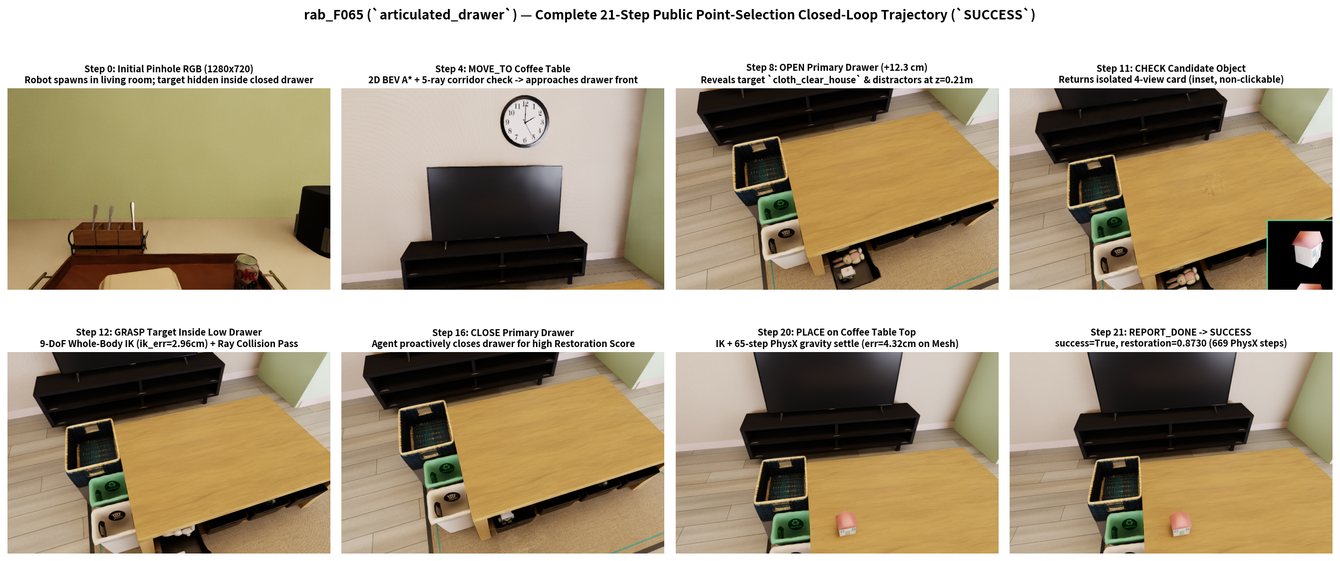

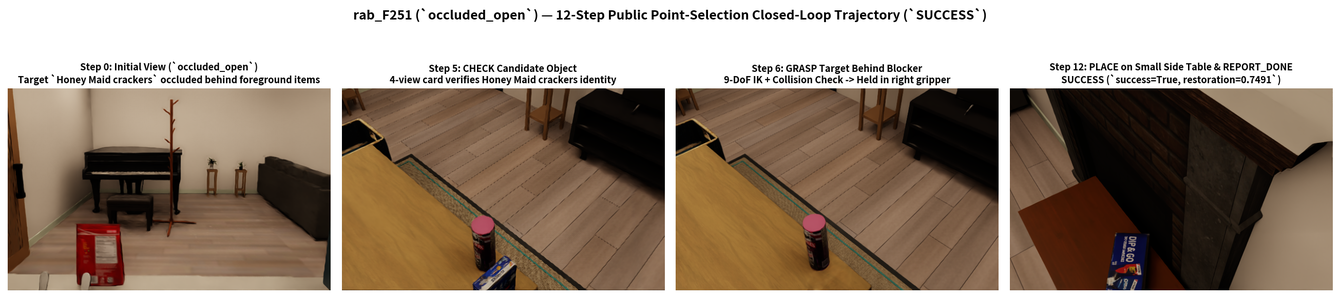

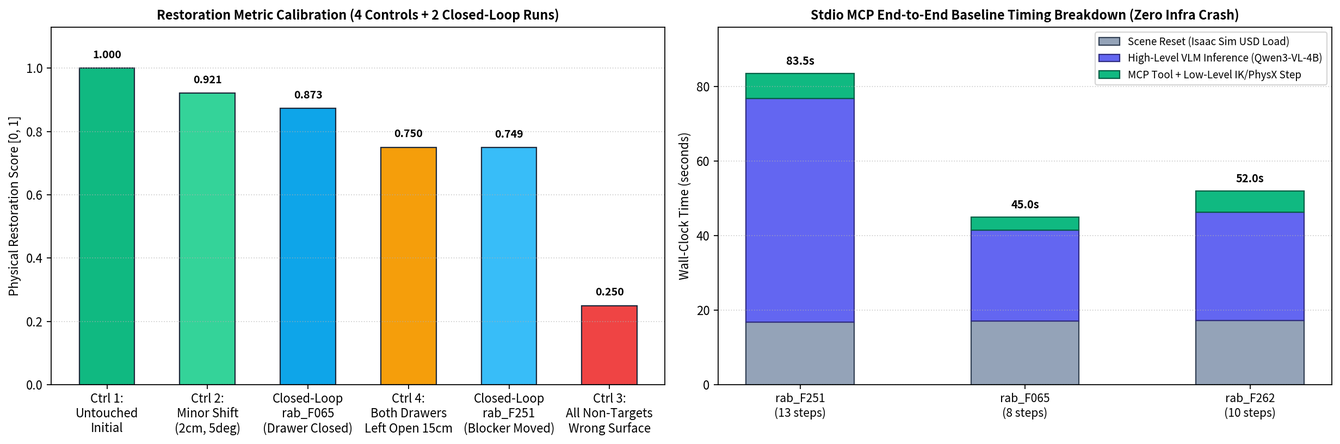

In [4]:
# 展示两条纯公开闭环 SUCCESS 轨迹连环画、复位标定曲线与 Qwen3-VL-4B 基线耗时/归因汇总
import json
RESULTS_SUMMARY = json.loads(r'''{
  "mcp_acceptance_13_of_13": {
    "ok": true,
    "total_wall_s": 72.863
  },
  "closed_loop_certificates": {
    "rab_F065_articulated_drawer": {
      "steps": 21,
      "status": "SUCCESS",
      "ik_error_m": 0.0296,
      "placement_error_m": 0.0432,
      "restoration": 0.873
    },
    "rab_F251_occluded_open": {
      "steps": 12,
      "status": "SUCCESS",
      "restoration": 0.7491
    }
  },
  "restoration_4_controls": {
    "1_untouched_initial": 1.0,
    "2_minor_shift_2cm_5deg": 0.9211,
    "3_wrong_support_all_non_targets": 0.25,
    "4_drawer_left_open_15cm": 0.7502
  },
  "baseline_qwen3_vl_4b_stdio_mcp": {
    "metrics": {
      "attempted_episodes": 3,
      "valid_episodes": 3,
      "invalid_infrastructure_episodes": 0,
      "success_count": 0,
      "SR": 0.0,
      "ST_wall_s": null,
      "ST_steps": null,
      "mean_steps_all_valid": 10.3333,
      "mean_wall_s_all_valid": 60.1315,
      "mean_model_wall_s": 37.8123,
      "mean_tool_sim_wall_s": 5.2765,
      "Restoration_mean": 0.9583
    },
    "failure_taxonomy_counts": {
      "high_level": {
        "H1_PREMATURE_REPORT_DONE_WITHOUT_GRASP": 3
      },
      "low_level": {
        "NONE_OBSERVED": 1,
        "L1_NAV_CLEARANCE_OR_ROUTE_REFUSAL": 2
      }
    }
  }
}''')
print(json.dumps(RESULTS_SUMMARY, indent=2, ensure_ascii=False))


---
## 六、下一步：正式进入 Metrics 指标体系设计的核心议题

现在整套数据（V2 全屋 10 区真实家庭布景）、物理引擎契约、零闲置开销的 MCP 服务、闭环可玩性证明与实验日志都已全部就位。接下来我们可以直接聚焦设计 **FindingBench v1 的正式 Metrics 体系**，核心待定维度如下：

1. **主任务成败与阶段性进度（`SR` + `Sub-goal Progress` + `False Completion Rate`）**：既保留最严格的终局交付成功率 `SR`，又给“找对并打开目标容器 $	o$ `CHECK`/看清目标 $	o$ 成功抓取 $	o$ 放对台面”设计可解释的阶段得分，并单独惩罚瞎报完成的 `FCR`。
2. **搜索效率指标（`Step-Weighted SR` / 重复开合冗余率）**：对照形式化期望步数或真人参考步数，量化空间记忆缺失导致的重复翻找开销。
3. **三段解耦耗时（`ST_model` vs `ST_skill_physx` vs `Reset`）**：把模型思考时间与机器人执行时间彻底分开报告。
4. **家庭友好度（`Restoration Score` 与 `UNSAFE` 违例率）**：确立复原度是与 `SR` 并列报告还是组合成 `Restoration-Gated SR`。
5. **高低层双层因果归因矩阵（`High-Level Planning Failure` vs `Low-Level Kinematic/Collision Bottleneck`）**：固化为论文主实验的核心诊断表格。
